# Classical RGT vs DNN vs hybrid (prototype)

A **classical, non-deep-learning RGT** built by dip-based global flattening (the principle behind PaleoScan / HorizonCube-type tools), compared with RGT-Est and combined with it.

**Classical method:**
1. **Local dips** everywhere, plus a quality value (how cleanly layered the seismic is).
2. **Lateral coherence:** how well each trace matches its neighbour along the dip. It's low across **faults** and in **chaos**, so it doubles as a discontinuity attribute.
3. **Flattening:** a stack of surfaces is solved so each follows the dips. The dips are only trusted **within continuous blocks**: links with low coherence are cut. Surfaces are pinned at the well and never cross.

Dips alone can't tell how far a block has moved across a fault. That information comes from a **reference**:
- **Classical + picks:** sparse picked horizons, spread through the stack, supply the fault throws.
- **Hybrid:** the RGT-Est (DNN) result supplies the throws and the broad structure; the dips fix its local errors.

**Scoring:** the miss against Jubilee and Ranger, as in the horizon lab. Sparse-pick versions are scored **only on un-picked traces**.

**Before you start:** **Runtime → Change runtime type → L4 GPU** (needed for the DNN; the classical part runs on CPU), then **Runtime → Run all**. Each classical run takes ~3–4 min; results are cached in Drive, and the DNN runs are shared with the horizon lab's cache.

## 1. Settings

In [1]:
DATA_SOURCE   = "drive"
DRIVE_FOLDER  = "/content/drive/MyDrive/PUBLIC"
DATA_FOLDER   = "/content"

MODEL_FILE    = "RGT-Est_CIG-Benchmark.pt"
SEGY_FILE     = "Full_Stack_8_41_CROP_1793889427461.sgy"
IL_BYTE, XL_BYTE = None, None
HORIZON_FILES = ["Jubilee.txt", "Ranger.txt"]       # used as sparse picks AND for scoring

INTERVAL_MS   = (1300, 2300)
WELL_IL, WELL_XL = 1123, 2098                       # reference trace: every surface is pinned here
SPARSE_PICK_EVERY = 10                              # picks on every Nth inline and crossline

N_SURFACES    = 200                                 # surfaces in the classical stack
OUTER_ITERS   = 6                                   # flattening iterations (~25 s each)
REF_SCALE     = 300                                 # hybrid: trust the reference (DNN / picks) for features broader than this (traces)
LINK_THRESHOLD = 0.7                                # coherence below which dip links are cut (faults, chaos)
CACHE         = True

## 2. Set up

In [2]:
!pip -q install segyio
import os, time, shutil, re, sys, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
warnings.filterwarnings("ignore", category=RuntimeWarning)
RUN_START = time.time()
print("PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

if DATA_SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    for f in [MODEL_FILE, SEGY_FILE] + list(HORIZON_FILES):
        src, dst = os.path.join(DRIVE_FOLDER, f), os.path.join(DATA_FOLDER, f)
        if not os.path.exists(src):
            print(f"not in Drive   {f}")
        elif not (os.path.exists(dst) and os.path.getsize(dst) == os.path.getsize(src)):
            shutil.copyfile(src, dst); print(f"copied         {f}")

def need(name):
    p = os.path.join(DATA_FOLDER, name)
    if not os.path.exists(p):
        raise FileNotFoundError(f"{name} not found. Files here: {sorted(os.listdir(DATA_FOLDER))}")
    return p
MODEL_PATH, SEGY_PATH = need(MODEL_FILE), need(SEGY_FILE)
HORIZON_PATHS = [need(h) for h in HORIZON_FILES]

!git clone -q https://github.com/fergusrssmith/RGT /content/RGT 2>/dev/null || git -C /content/RGT pull -q
sys.path[:0] = ["/content/RGT/colab", "/content/RGT/demo"]
import importlib, rgt_lfm as R, rgt_lab as L, rgt_classic as C
for m in (R, L, C): importlib.reload(m)

BASE = DRIVE_FOLDER if DATA_SOURCE == "drive" else DATA_FOLDER
OUT_DIR = os.path.join(BASE, "outputs", time.strftime("%Y-%m-%d_%H%M", time.gmtime(RUN_START)) + "_classic")
CACHE_DIR = os.path.join(BASE, "outputs", "_rgt_cache")
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(CACHE_DIR, exist_ok=True)
print("outputs →", OUT_DIR)

PyTorch 2.14.1+cu130 | GPU: NVIDIA L4
Mounted at /content/drive
copied         RGT-Est_CIG-Benchmark.pt
copied         Full_Stack_8_41_CROP_1793889427461.sgy
copied         Jubilee.txt
copied         Ranger.txt
outputs → /content/drive/MyDrive/PUBLIC/outputs/2026-11-10_1217_classic


## 3. Seismic and horizons

In [3]:
G = R.read_segy_cube(SEGY_PATH, IL_BYTE, XL_BYTE)
cube, ilines, xlines, samples, dt = G["cube"], G["ilines"], G["xlines"], G["samples"], G["dt"]
NI, NX, NT = cube.shape
ci = int(np.searchsorted(ilines, WELL_IL)) if WELL_IL in ilines else NI // 2
cx = int(np.searchsorted(xlines, WELL_XL)) if WELL_XL in xlines else NX // 2
REF = (ci, cx)
HZ = sorted([L.read_rokdoc_horizon(p, ilines, xlines, samples) for p in HORIZON_PATHS], key=lambda h: np.nanmean(h["t"]))
HZ_SPARSE = [dict(name=h["name"], t=L.sparsify(h["t"], SPARSE_PICK_EVERY)) for h in HZ]
NOT_PICKED = ~np.isfinite(HZ_SPARSE[0]["t"])
GUIDES = [(h["t"] - samples[0]) / dt for h in HZ_SPARSE]           # sparse picks in time-sample index
print(f"{NI} inlines × {NX} crosslines × {NT} samples; reference trace inline {ilines[ci]}, crossline {xlines[cx]}")
print(f"sparse picks: every {SPARSE_PICK_EVERY}th line = {100*(~NOT_PICKED).mean():.0f}% of traces")
vclip = np.percentile(np.abs(cube), 99)
EXT_IL = (xlines[0], xlines[-1], samples[-1], samples[0])
EXT_XL = (ilines[0], ilines[-1], samples[-1], samples[0])

256 inlines × 512 crosslines × 400 samples; reference trace inline 1123, crossline 2098
sparse picks: every 10th line = 19% of traces


## 4. DNN (RGT-Est) runs: unguided and guided by the sparse picks

These use the same cache as the horizon lab, so if the lab has already run, they load instantly.

In [4]:
import torch.nn as nn, torch.nn.functional as F
from scipy.ndimage import grey_dilation
device = "cuda" if torch.cuda.is_available() else "cpu"
GRID = (400, 512, 512)
def z_score_clip(d, c=2.0):
    z = np.clip((d - d.mean()) / (d.std() + 1e-8), -c, c); return (z - z.min()) / (z.max() - z.min() + 1e-6)
seis_norm = z_score_clip(cube) * 2 - 1

def guidance_volume(use):
    ids = np.zeros((NI, NX, NT), np.int16)
    for k, h in enumerate(use, 1):
        i, j = np.nonzero(np.isfinite(h["t"]))
        ids[i, j, np.clip(np.round((h["t"][i, j] - samples[0]) / dt).astype(int), 0, NT - 1)] = k
    ids = grey_dilation(ids, size=2)
    vol = np.zeros((NI, NX, NT), np.float32)
    for k, h in enumerate(use, 1):
        vol[ids == k] = (np.nanmean(h["t"]) - samples[0]) / dt / NT * 2 - 1
    return vol

_model = {}
def run_rgt(use):
    if "m" not in _model:
        _model["m"] = torch.jit.load(MODEL_PATH, map_location=device).eval()
    s = F.interpolate(torch.from_numpy(seis_norm.transpose(2, 0, 1).copy())[None, None], GRID, mode="trilinear")
    g = torch.zeros_like(s) if not use else \
        F.interpolate(torch.from_numpy(guidance_volume(use).transpose(2, 0, 1).copy())[None, None], GRID, mode="nearest")
    x = torch.cat([s, g, (g != 0).float()], dim=1).to(device)
    with torch.no_grad(), torch.autocast(device_type=device):
        r = _model["m"](nn.ReplicationPad3d(8)(x))[:, :, 8:-8, 8:-8, 8:-8]
    out = F.interpolate(r.float(), (NT, NI, NX), mode="trilinear").cpu().numpy()[0, 0]
    del x, r
    if device == "cuda": torch.cuda.empty_cache()
    return z_score_clip(out).transpose(1, 2, 0).astype(np.float32)

st = os.stat(SEGY_PATH)
SEIS_KEY = f"{os.path.splitext(SEGY_FILE)[0]}_{st.st_size}_{int(st.st_mtime)}"
def cache_path(key):
    return os.path.join(CACHE_DIR, re.sub(r"[^A-Za-z0-9_.+-]", "_", SEIS_KEY + "_" + key) + ".npy")
def cached(label, key, fn):
    path = cache_path(key)
    if CACHE and os.path.exists(path):
        print(f"{label}: from cache"); return np.load(path)
    t0 = time.time(); print(f"{label}: computing ..."); out = fn()
    print(f"   {time.time()-t0:.0f} s")
    if CACHE: np.save(path, out)
    return out
hz_key = lambda use, tag: tag + "_" + "+".join(f"{h['name']}-{int(np.nansum(h['t'])*10) % 10**8}" for h in use)

RGT = {}
RGT["DNN"] = cached("DNN unguided", "unguided", lambda: run_rgt([]))
RGT["DNN + picks"] = cached("DNN guided by sparse picks", hz_key(HZ_SPARSE, f"sparse{SPARSE_PICK_EVERY}"), lambda: run_rgt(HZ_SPARSE))

DNN unguided: computing ...


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


   10 s
DNN guided by sparse picks: computing ...
   9 s


## 5. Dips, quality and coherence (the classical method's inputs)

The **coherence** panel is a discontinuity attribute in its own right: dark lines are faults, and dark patches are chaotic zones.

dips, quality and coherence: 60 s


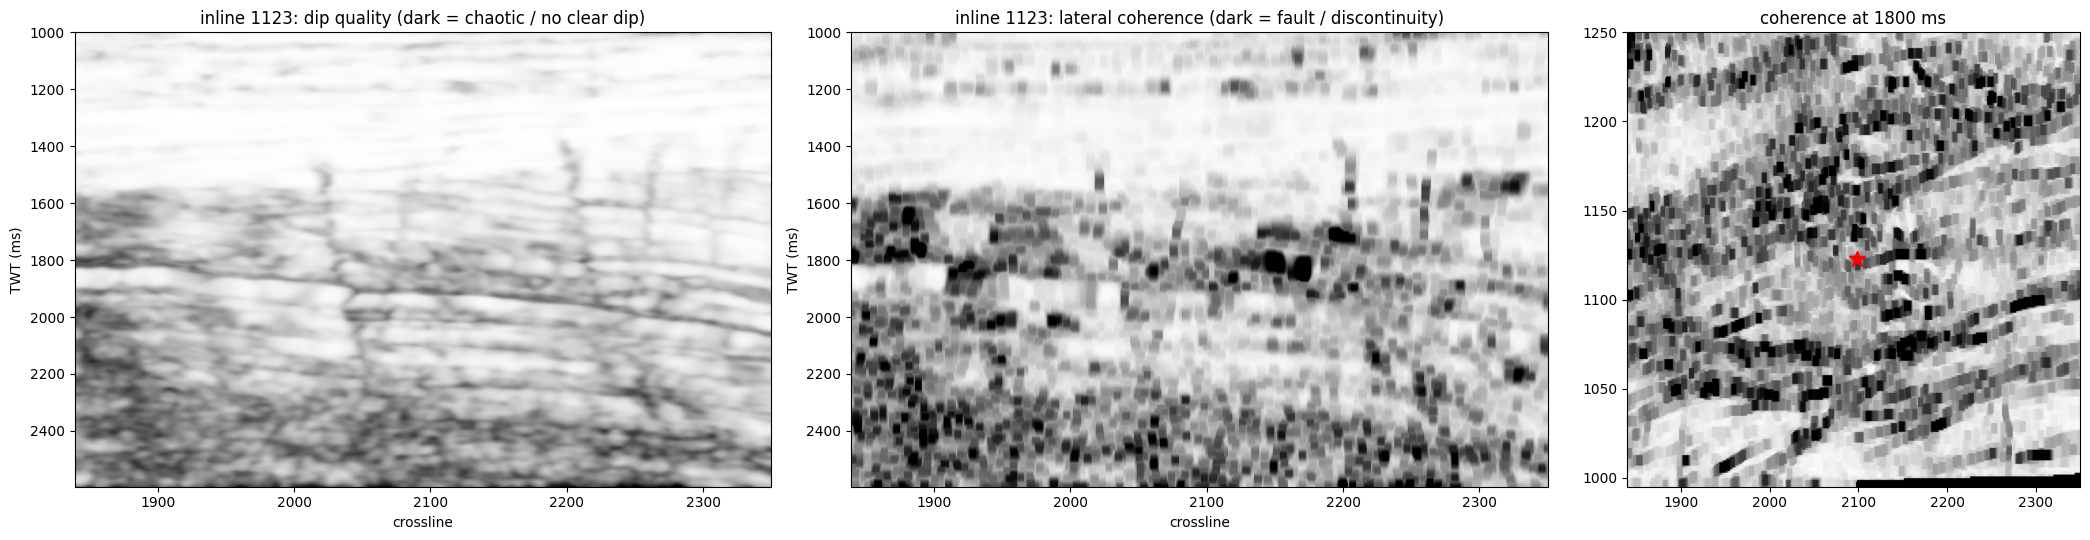

In [5]:
t0 = time.time()
p, q, qual, LINKS = C.fault_aware_dips(cube)
print(f"dips, quality and coherence: {time.time()-t0:.0f} s")
coh = C.voxel_weight_from_links(LINKS, power=1)
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5), gridspec_kw={"width_ratios": [2, 2, 1.3]})
axes[0].imshow(qual[ci].T, cmap="gray", vmin=0, vmax=1, aspect="auto", extent=EXT_IL)
axes[0].set_title(f"inline {ilines[ci]}: dip quality (dark = chaotic / no clear dip)")
axes[1].imshow(coh[ci].T, cmap="gray", vmin=0, vmax=1, aspect="auto", extent=EXT_IL)
axes[1].set_title(f"inline {ilines[ci]}: lateral coherence (dark = fault / discontinuity)")
k = int(np.clip(round((sum(INTERVAL_MS) / 2 - samples[0]) / dt), 0, NT - 1))
axes[2].imshow(coh[:, :, k], cmap="gray", vmin=0, vmax=1, origin="lower", aspect="auto",
               extent=(xlines[0], xlines[-1], ilines[0], ilines[-1]))
axes[2].plot(xlines[cx], ilines[ci], "r*", ms=12); axes[2].set_title(f"coherence at {samples[k]:.0f} ms")
for ax in axes[:2]: ax.set_ylabel("TWT (ms)"); ax.set_xlabel("crossline")
fig.tight_layout(); plt.show()

## 6. Classical and hybrid runs

| Run | Starting point | Reference (sets fault throws / broad shape) | Picks pinned |
|---|---|---|---|
| **Classical** | flat | none | none |
| **Classical + picks** | picks spread through the stack | the same | yes |
| **Hybrid** | DNN surfaces | DNN unguided | none |
| **Hybrid + picks** | DNN-with-picks surfaces | DNN guided by the picks | yes |

In [6]:
kw = dict(n_surfaces=N_SURFACES, links=LINKS, outer_iters=OUTER_ITERS, ref_scale=REF_SCALE, link_threshold=LINK_THRESHOLD)
skey = f"classic_K{N_SURFACES}_it{OUTER_ITERS}_s{REF_SCALE}_lt{LINK_THRESHOLD}_ref{ci}-{cx}"
SURF = {}
SURF["Classical"] = cached("Classical", skey + "_plain", lambda: C.flatten(p, q, qual, REF, **kw))
def classic_picks():
    rg = C.reference_from_guides(SURF["Classical"], GUIDES, REF, NT)
    return C.flatten(p, q, qual, REF, init=rg, reference=rg, guides=GUIDES, **kw)
SURF["Classical + picks"] = cached("Classical + picks", skey + "_" + hz_key(HZ_SPARSE, f"picks{SPARSE_PICK_EVERY}"), classic_picks)
def hybrid(dnn, guides=None):
    zd = C.surfaces_from_rgt(dnn, REF, N_SURFACES)
    return C.flatten(p, q, qual, REF, init=zd, reference=zd, guides=guides, **kw)
SURF["Hybrid"] = cached("Hybrid (DNN + dips)", skey + "_hybrid", lambda: hybrid(RGT["DNN"]))
SURF["Hybrid + picks"] = cached("Hybrid + picks", skey + "_" + hz_key(HZ_SPARSE, f"hybridpicks{SPARSE_PICK_EVERY}"),
                                lambda: hybrid(RGT["DNN + picks"], GUIDES))
for name, z in SURF.items():
    RGT[name] = C.rgt_from_surfaces(z, NT)
print("RGT versions:", list(RGT))

Classical: computing ...
   iteration 1/6: mean surface change 2.173 samples  (34 s)
   iteration 2/6: mean surface change 1.207 samples  (67 s)
   iteration 3/6: mean surface change 0.823 samples  (101 s)
   iteration 4/6: mean surface change 0.614 samples  (134 s)
   iteration 5/6: mean surface change 0.484 samples  (168 s)
   iteration 6/6: mean surface change 0.396 samples  (202 s)
   202 s
Classical + picks: computing ...
   iteration 1/6: mean surface change 1.042 samples  (36 s)
   iteration 2/6: mean surface change 0.380 samples  (70 s)
   iteration 3/6: mean surface change 0.180 samples  (105 s)
   iteration 4/6: mean surface change 0.105 samples  (140 s)
   iteration 5/6: mean surface change 0.067 samples  (175 s)
   iteration 6/6: mean surface change 0.045 samples  (210 s)
   212 s
Hybrid (DNN + dips): computing ...
   iteration 1/6: mean surface change 0.610 samples  (35 s)
   iteration 2/6: mean surface change 0.209 samples  (70 s)
   iteration 3/6: mean surface change 0.0

## 7. Scores

Vertical miss (ms) between Jubilee/Ranger and the best-matching surface of each RGT, and the hit rate within 2 samples.
Versions that saw the picks are scored **only on traces that weren't picked**. The rest are scored on all traces.

In [7]:
rows = []
for name, vol in RGT.items():
    uses_picks = "picks" in name
    res = L.horizon_errors(vol, HZ, samples, mask=NOT_PICKED if uses_picks else None)
    rows.append(dict(version=name, **{f"{h['name']} miss (ms)": e for h, (e, _) in zip(HZ, res)},
                     **{f"{h['name']} hit %": r for h, (_, r) in zip(HZ, res)},
                     mean_miss_ms=np.mean([e for e, _ in res]),
                     scored_on="un-picked traces" if uses_picks else "all traces"))
scores = pd.DataFrame(rows)
print(scores.round(1).to_string(index=False))

          version  Ranger miss (ms)  Jubilee miss (ms)  Ranger hit %  Jubilee hit %  mean_miss_ms        scored_on
              DNN               9.2               42.3          57.5           20.7          25.8       all traces
      DNN + picks               5.1                3.4          80.1           91.8           4.3 un-picked traces
        Classical              28.4               78.2          40.7            9.6          53.3       all traces
Classical + picks               1.0                1.7          99.8           96.5           1.4 un-picked traces
           Hybrid               9.7               42.0          55.2           22.9          25.8       all traces
   Hybrid + picks               2.1                1.8          94.8           95.6           2.0 un-picked traces


## 8. Sections and flattened views

**Top:** seismic with each version's RGT contours, plus the interpreted horizons as magenta dashes. **Bottom:** the same inline flattened. Reflections should be flat where the RGT is right.

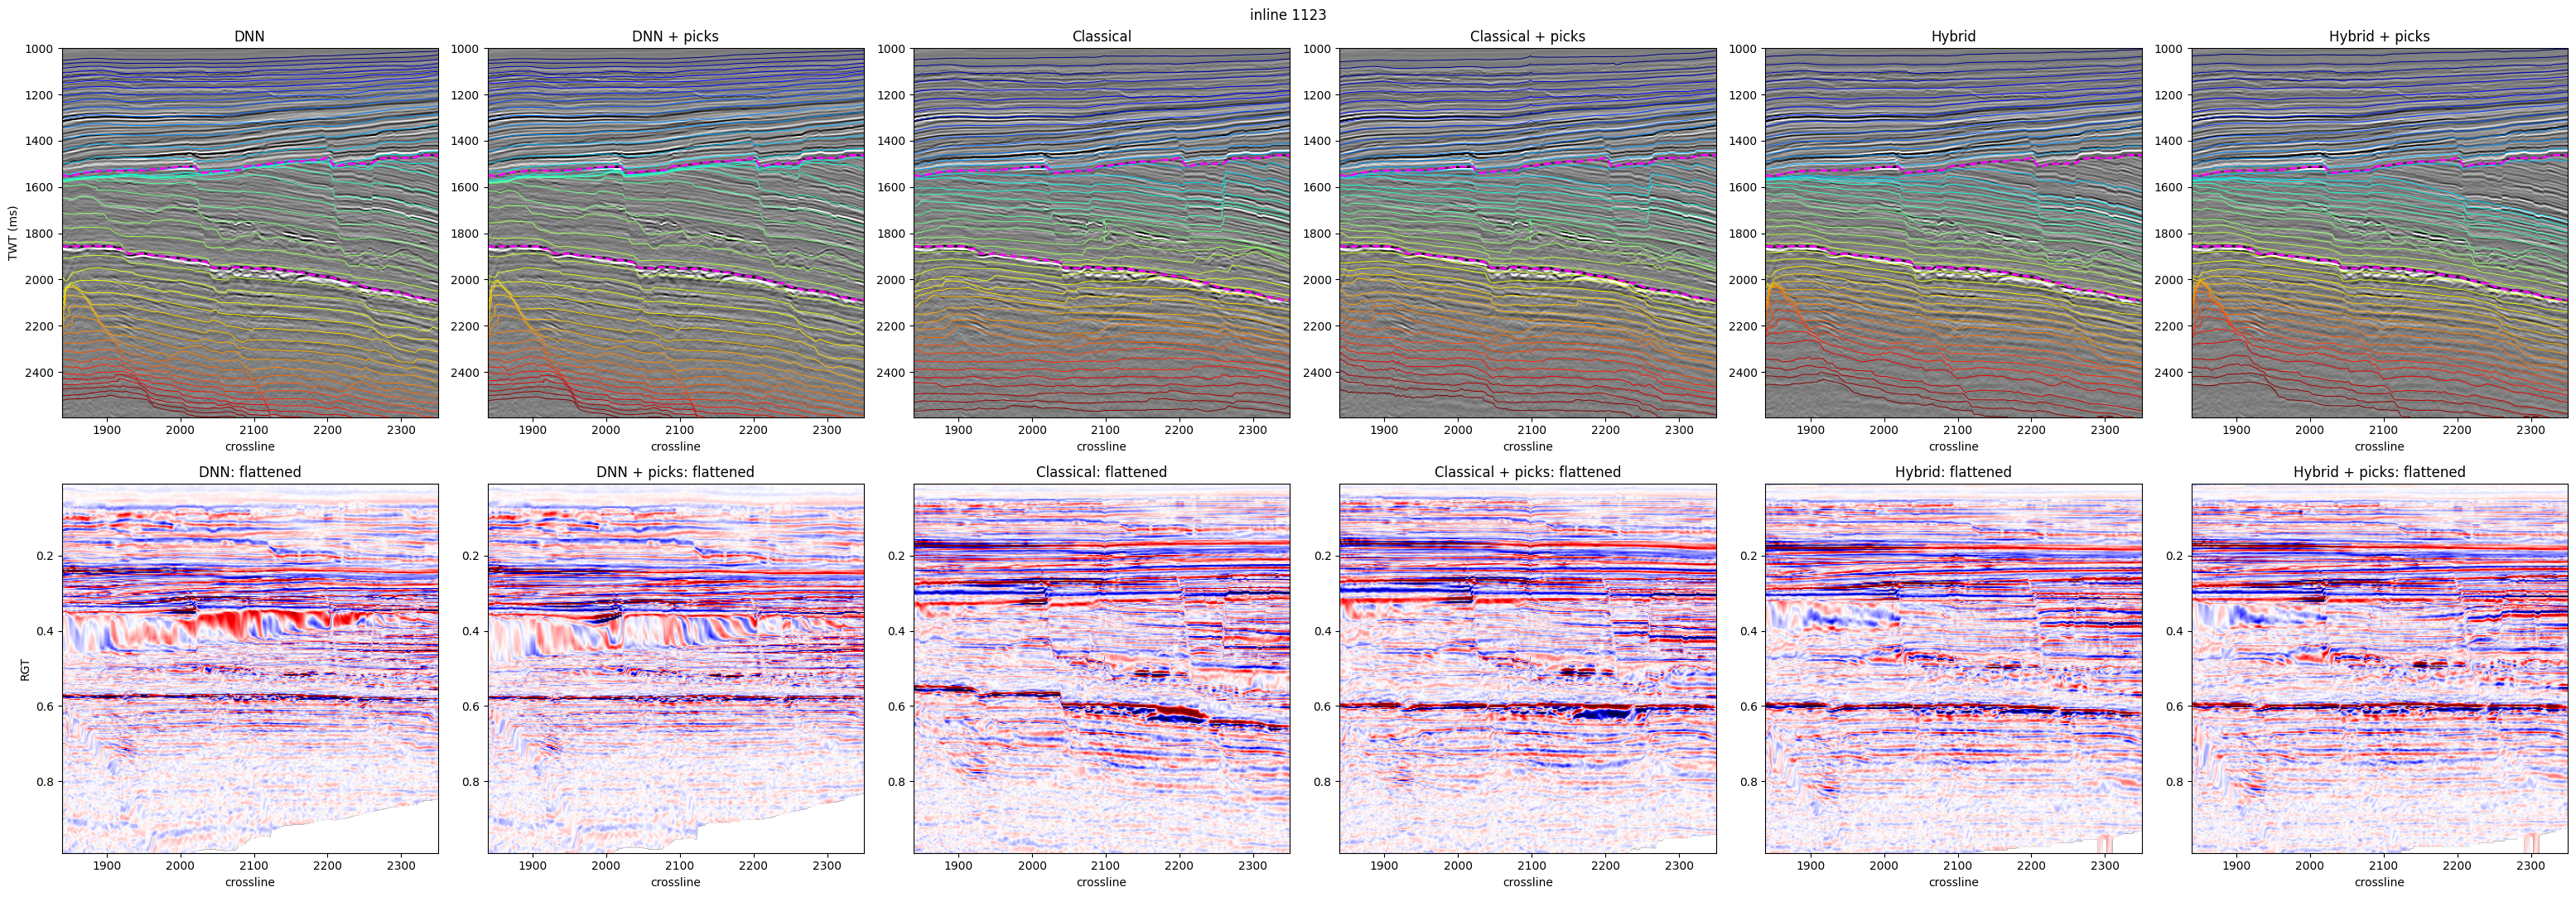

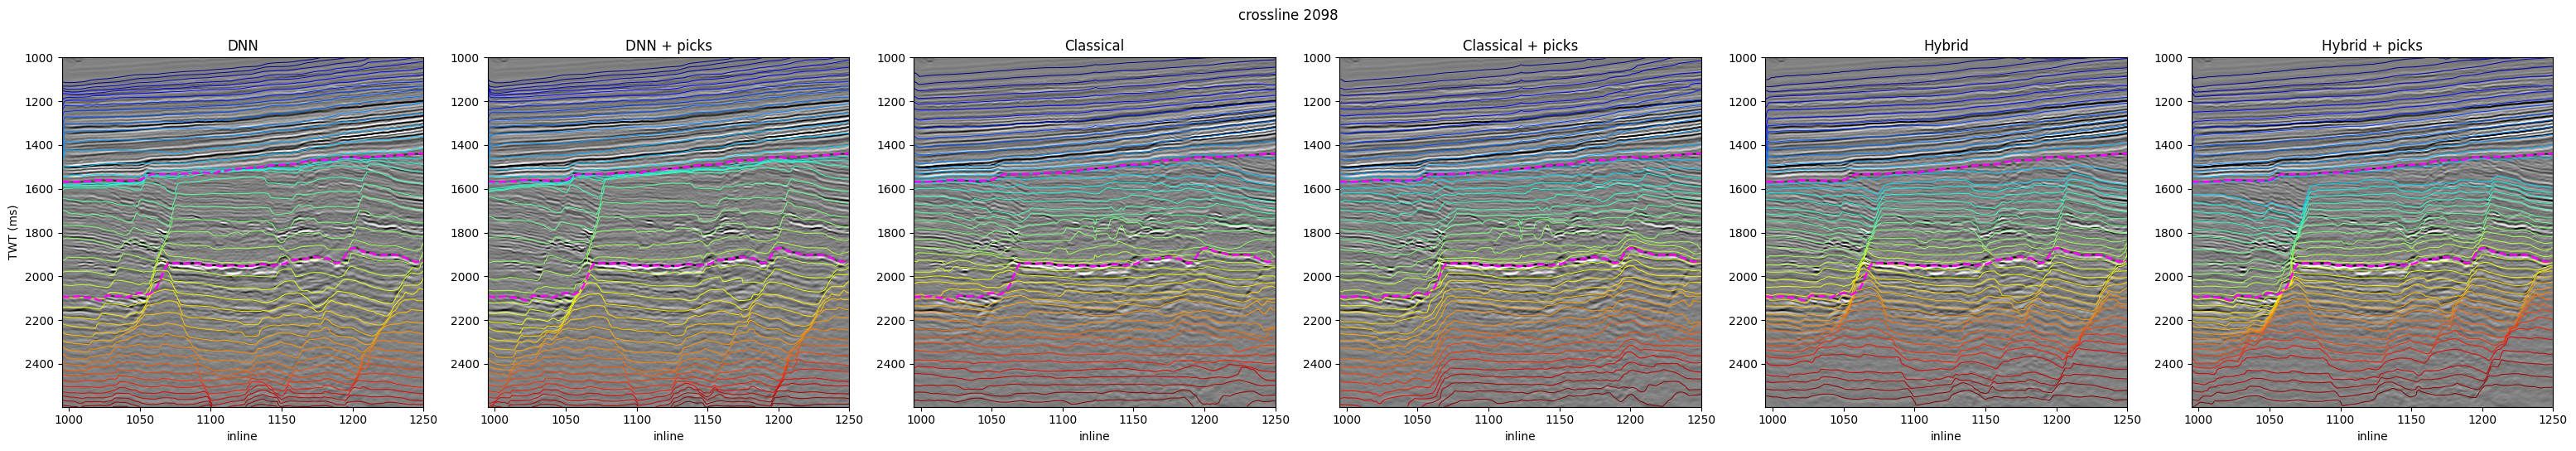

In [8]:
names = list(RGT)
levels_c = np.linspace(0.02, 0.98, 45)
fig, axes = plt.subplots(2, len(names), figsize=(5.2 * len(names), 11))
lv = np.linspace(0.01, 0.99, 400)
for col, name in enumerate(names):
    ax = axes[0, col]
    ax.imshow(cube[ci].T, cmap="gray", aspect="auto", vmin=-vclip, vmax=vclip, extent=EXT_IL)
    ax.contour(RGT[name][ci].T, levels=levels_c, cmap="jet", linewidths=0.7, extent=(xlines[0], xlines[-1], samples[0], samples[-1]))
    for h in HZ:
        ax.plot(xlines, h["t"][ci], color="magenta", lw=1.8, ls="--")
    ax.set_title(name); ax.set_ylim(samples[-1], samples[0]); ax.set_xlabel("crossline")
    flat, _ = L.flatten_section(cube[ci], RGT[name][ci], samples, lv)
    axes[1, col].imshow(flat, cmap="seismic_r", aspect="auto", vmin=-vclip, vmax=vclip, extent=(xlines[0], xlines[-1], lv[-1], lv[0]))
    axes[1, col].set_title(f"{name}: flattened"); axes[1, col].set_xlabel("crossline")
axes[0, 0].set_ylabel("TWT (ms)"); axes[1, 0].set_ylabel("RGT")
fig.suptitle(f"inline {ilines[ci]}"); fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(names), figsize=(5.2 * len(names), 5.5))
for ax, name in zip(axes, names):
    ax.imshow(cube[:, cx].T, cmap="gray", aspect="auto", vmin=-vclip, vmax=vclip, extent=EXT_XL)
    ax.contour(RGT[name][:, cx].T, levels=levels_c, cmap="jet", linewidths=0.7, extent=(ilines[0], ilines[-1], samples[0], samples[-1]))
    for h in HZ:
        ax.plot(ilines, h["t"][:, cx], color="magenta", lw=1.8, ls="--")
    ax.set_title(name); ax.set_ylim(samples[-1], samples[0]); ax.set_xlabel("inline")
axes[0].set_ylabel("TWT (ms)"); fig.suptitle(f"crossline {xlines[cx]}"); fig.tight_layout(); plt.show()

## 9. Save (SEG-Y, headers copied from the input)

In [9]:
import segyio
stem = os.path.splitext(os.path.basename(SEGY_PATH))[0]
def write_like_input(volume, tag):
    path = os.path.join(OUT_DIR, f"{stem}_{tag}.sgy")
    shutil.copyfile(SEGY_PATH, path)
    with segyio.open(path, "r+", ignore_geometry=True) as f:
        for k in range(G["n_tr"]):
            f.trace[k] = np.ascontiguousarray(volume[G["il_idx"][k], G["xl_idx"][k]], dtype=np.float32)
    print("wrote", os.path.basename(path))
for name in ("Classical", "Classical + picks", "Hybrid", "Hybrid + picks"):
    write_like_input(RGT[name], "RGT_" + re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_"))
write_like_input(coh, "coherence")
scores.to_csv(os.path.join(OUT_DIR, f"{stem}_classic_vs_dnn_scores.csv"), index=False)
print("all outputs in", OUT_DIR)

wrote Full_Stack_8_41_CROP_1793889427461_RGT_Classical.sgy
wrote Full_Stack_8_41_CROP_1793889427461_RGT_Classical_picks.sgy
wrote Full_Stack_8_41_CROP_1793889427461_RGT_Hybrid.sgy
wrote Full_Stack_8_41_CROP_1793889427461_RGT_Hybrid_picks.sgy
wrote Full_Stack_8_41_CROP_1793889427461_coherence.sgy
all outputs in /content/drive/MyDrive/PUBLIC/outputs/2026-11-10_1217_classic
